# Aging lung atlas (Angelidis)

An atlas of the aging lung mapped by single cell transcriptomics and deep tissue proteomics (Angelidis et al, 2019). Dataset of whole-lung cells from **3-month-old** mice (n=8) and **24 month-old** mice (n=7). In total, **14,813 cells** (7672 young cells, 7141 old). Data were obtained from the Gene Expression Omnibus (GEO): **GSE124872**. 

In this notebook we:
* Load Angelidis dataset. On the one hand, we load the gene expression matrix (`angelidis_matrix.csv`). On the other hand, we load the metadata file (`GSE124872_Angelidis_2018_metadata.csv`). We create an annData object to store the gene expression matrix and the metadata (`adata_all`)
* Preprocessing and normalization
* Compute DEGs between each cell type cluster and the rest of the cells. These DEGs will be used to annotate other lung datasets (Kimmel, Tabula muris senis lung droplet and Tabula muris senis lung FACS) using the software scoreCT.
* Create two annData objects: `adata_young` and `adata_old`
* Create table with cell type composition in young and old samples.
* Downsampling of counts so that the young and the old dataset have a comparable number of counts/cell
* Downsampling of cells so that the young and the old dataset have the same amount of cells per cell type
* Write the two annData objects


**INPUT**:
* `angelidis_matrix.csv`: Angelidis single-cell RNAseq expression matrix. 
* `GSE124872_Angelidis_2018_metadata.csv`: Angelidis metadata. 
* `colorlist.csv`: custom palette that we will use across all mouse lung datasets. It was designed to plot similar cell types with different shades of the same hue. 


**OUTPUT**: 
* `Angelidis_annotated.h5ad`: annData object containing the normalized and preprocessed gene expression data + metadata + cell type annotations. 
* `Angelidis_ct_markers.csv`: DEGs between cell types in the dataset. These will be used as input for scoreCT to automatically annotate other lung mouse datasets. 
* `angelidis_young_annotated.h5ad` and `angelidis_old_annotated.h5ad`: annData objects of the young and old mouse lung cells, after normalization, preprocessing and cell-type annotation.
* `Angelidis_cell_type_composition.csv`: table with cell-type composition
* `angelidis_young_balanced.h5ad` and `angelidis_old_balanced.h5ad`: annData objects of the young and old mouse lung cells, after normalization, preprocessing and cell-type annotation, and where cells have been downsampled so that the cell type composition of the two datasets is equal.

In [1]:
# Data analysis & stats
import pandas as pd
import numpy as np
from scipy.stats import ranksums
from scipy.sparse import csr_matrix

# Single-cell
import scanpy as sc
import scanpy.external as sce
import anndata

# Plotting & palettes
import matplotlib.pyplot as plt
import seaborn as sns
from palettable.cartocolors.qualitative import Pastel_10, Safe_10, Bold_10, Vivid_10, Prism_10, Antique_5
from palettable.colorbrewer.qualitative import Set3_12


seed=10
name_dataset = 'Angelidis'

# Palettes

We use a custom palette for lung cell types, where cell types that share more similarities are plotted with different shades of the same hue. This palette is used on all the lung datasets to make comparisons between them easier.   

In [2]:
bold, safe, vivid, prism  = Bold_10.hex_colors, Safe_10.hex_colors, Vivid_10.hex_colors, Prism_10.hex_colors

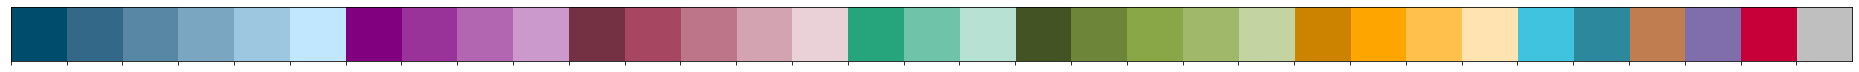

In [3]:
mypal = pd.read_csv('../../data/palettes/Cell_type_palette.csv', index_col=0)['color_manual']
mypal_dic = dict(mypal)
sns.palplot(mypal.values.tolist())

# Load dataset & metadata
The gene expression matrix and metadata files were both obtained from the Gene Expression Omnibus (GEO): GSE124872. 

In [3]:
adata_all = sc.read_csv('../../data/raw_data/angelidis/angelidis_matrix.csv').transpose()

In [9]:
metadata = pd.read_csv('../../data/raw_data/angelidis/GSE124872_Angelidis_2018_metadata.csv', index_col=0)

In [9]:
metadata

,nGene,nUMI,orig.ident,identifier,res.2,identifier.1,name,grouping,batch,cells,cluster,celltype
muc3838:muc3838:TTCCGTGCCCCT,4255,10691,merged,muc3838,2,muc3838,NaN,24m,good,800,cluster2,Ciliated_cells
muc3838:muc3838:TTGCCCAATTAA,3178,6860,merged,muc3838,2,muc3838,NaN,24m,good,800,cluster2,Ciliated_cells
muc3838:muc3838:AAGCCCAGCTAT,1470,6127,merged,muc3838,24,muc3838,NaN,24m,good,800,cluster24,Plasma_cells
muc3838:muc3838:GCACTTTAGAAT,2348,4359,merged,muc3838,2,muc3838,NaN,24m,good,800,cluster2,Ciliated_cells
muc3838:muc3838:TCCTGCTCCCTT,2439,5293,merged,muc3838,2,muc3838,NaN,24m,good,800,cluster2,Ciliated_cells
...,...,...,...,...,...,...,...,...,...,...,...,...
muc4657:muc4657:ATCAAGACAGTG,340,670,merged,muc4657,0,muc4657,NaN,3m,good,1000,cluster0,Type_2_pneumocytes
muc4657:muc4657:GACTGCGCATGG,223,263,merged,muc4657,2,muc4657,NaN,3m,good,1000,cluster2,Ciliated_cells
muc4657:muc4657:ATGACCGAATGT,240,436,merged,muc4657,0,muc4657,NaN,3m,good,1000,cluster0,Type_2_pneumocytes
muc4657:muc4657:GTGTTTGGACCG,668,1081,merged,muc4657,9,muc4657,NaN,3m,good,1000,cluster9,Cd4+_T_cells


In [10]:
# Check that the number of cells is equal in the annData and in the metadata
metadata.shape, adata_all.shape

((14813, 12), (14813, 21969))

In [11]:
metadata['id'] = adata_all.obs_names

In [12]:
# Check that the cell names are the same in metadata and in annData
set([(a.split(':')[-1] == b.split(':')[-1]) for (a, b) in zip(metadata['id'].values.tolist(), metadata.index.values.tolist())])

{True}

In [13]:
metadata = metadata.set_index('id')

In [14]:
# Add metadata into the obs slot of annData
adata_all.obs['cell_type'] = metadata['celltype']
adata_all.obs['age'] = metadata['grouping']
adata_all.obs['cluster'] = metadata['cluster']
adata_all.obs['mouse'] = metadata['identifier']

In [11]:
# Remove any null observations
adata_all = adata_all[~adata_all.obs['cell_type'].isnull()]

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1094: FutureWarning: is_categorical is deprecated and will be removed in a future version.  Use is_categorical_dtype instead
  if not is_categorical(df_full[k]):


In [12]:
# A bit of editing of the cell type names from Angelidis:
    # Capitalize all names for consistency
    # Replace underscores ('_') with spaces (' ')
    # Change "Type1 pneumocytes" to "Type 1 pneumocytes" 
adata_all.obs['cell_type'] = [nam.capitalize().replace('_', ' ') for nam in adata_all.obs['cell_type']]
adata_all.obs['cell_type'] = [nam.replace('Type1', 'Type 1') for nam in adata_all.obs['cell_type']]

Trying to set attribute `.obs` of view, copying.


# Normalization & preprocessing
Normalization and preprocessing include: 
* Filtering cells that express fewer than 200 genes
* Filtering genes that are expressed in fewer than 3 cells
* Normalizing total counts to 1e4
* Log-transformation
* Selection of highly variable genes (used in the computation of the PCA)
* Principal Component Analysis (PCA)
* BBKNN (computation of the neighbor graph with batch-effect correction
* UMAP dimensionality reduction

In [23]:
def normalization(adata):
    sc.pp.filter_cells(adata, min_genes=200)
    sc.pp.filter_genes(adata, min_cells=3)
    sc.pp.calculate_qc_metrics(adata, inplace=True)
    adata.var_names_make_unique()
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    return adata

In [24]:
def preprocessing(adata, batch_key):
    sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=8, min_disp=0.1)
    sc.pp.pca(adata)
    if batch_key is None:
        print('Batch key is None, computing neighbors')
        sc.pp.neighbors(adata)
    else: 
        print(f'Using {batch_key} as batch_key to compute bbknn')
        sce.pp.bbknn(adata, batch_key=batch_key)
    sc.tl.umap(adata)
    return adata

In [15]:
# Convert arrays to sparse (some datasets come as dense arrays)
adata_all.X = csr_matrix(adata_all.X)

In [16]:
# In the Angelidis dataset, 2 cells were labeled as "low quality cells" -- remove them
adata_all = adata_all[adata_all.obs['cell_type'] != 'Low quality cells']

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1094: FutureWarning: is_categorical is deprecated and will be removed in a future version.  Use is_categorical_dtype instead
  if not is_categorical(df_full[k]):


In [17]:
adata_all = normalization(adata_all)

Trying to set attribute `.obs` of view, copying.


In [18]:
adata_all = preprocessing(adata_all, batch_key='mouse')

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1094: FutureWarning: is_categorical is deprecated and will be removed in a future version.  Use is_categorical_dtype instead
  if not is_categorical(df_full[k]):


Using mouse as batch_key to compute bbknn


/home/amon/anaconda3/lib/python3.7/site-packages/bbknn/__init__.py:289: FutureWarning: This location for 'distances' is deprecated. It has been moved to .obsp[distances], and will not be accesible here in a future version of anndata.
  adata.uns['neighbors']['distances'] = bbknn_out[0]
/home/amon/anaconda3/lib/python3.7/site-packages/bbknn/__init__.py:290: FutureWarning: This location for 'connectivities' is deprecated. It has been moved to .obsp[connectivities], and will not be accesible here in a future version of anndata.
  adata.uns['neighbors']['connectivities'] = bbknn_out[1]


# UMAPs

Here we observe the general structure of the dataset and we check that there are no big batch effects between samples or individual mice. 

* **Cell types**: the labels provided by Angelidis et al. We can see that cell-type labels correspond to clusters that are well separated on the UMAP projection. 
* **Mouse**: we can see that there are no obvious batch effects related to the individual mice the cells were drawn from, as all of the mice are represented in all or most of the cell clusters. 
* **Age**: even though some cell types are more abundant in one of the age groups, we can see that the two age groups are represented in all of the clusters. 

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1192: FutureWarning: is_categorical is deprecated and will be removed in a future version.  Use is_categorical_dtype instead
  if is_string_dtype(df[key]) and not is_categorical(df[key])
... storing 'cell_type' as categorical
... storing 'age' as categorical
... storing 'cluster' as categorical
... storing 'mouse' as categorical


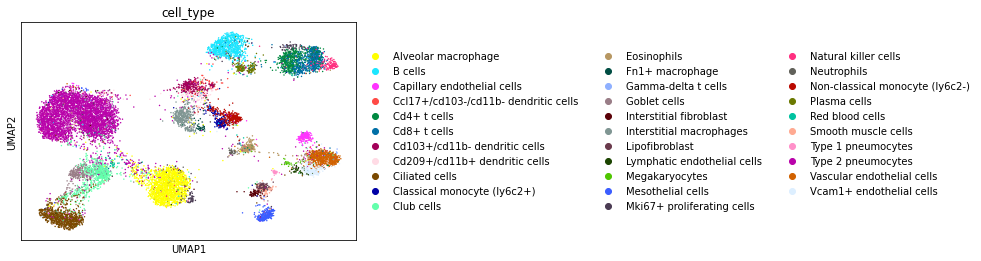

In [19]:
sc.pl.umap(adata_all, color=['cell_type'])

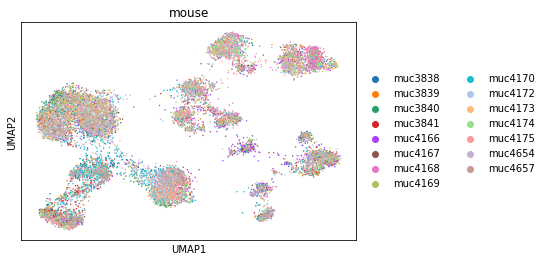

In [20]:
sc.pl.umap(adata_all, color=['mouse'])

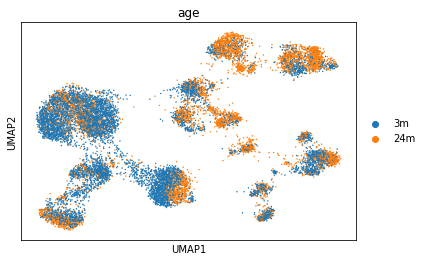

In [21]:
sc.pl.umap(adata_all, color=['age'])

# Output: annotated annDatas

The `Angelidis_annotated.h5ad` file contains the normalized and preprocessed gene expression data and the metadata of the Angelidis dataset.

In [ ]:
adata_all.write('../../data/anndatas/annotated/Angelidis_annotated.h5ad')

# Start from annotated annData

In [4]:
adata = sc.read_h5ad('../../data/anndatas/annotated/Angelidis_annotated.h5ad')

# DEGs between cell types
We need to compute the differentially expressed genes (DEGs) between the cell types present in the Angelidis dataset in order to be able to project those cell type labels onto the rest of the mouse lung datasets. Output: `Angelidis_ct_markers.csv`. 

In [5]:
sc.tl.rank_genes_groups(adata, groupby='cell_type')

In [6]:
pd.DataFrame(adata.uns['rank_genes_groups']['names']).to_csv('../../output/tables/Angelidis_ct_markers.csv')

# Create two annData objects: young (3 month) and old (24 month)

In [7]:
# Create two annData objects for the young and old mice cells
adata_young = adata[adata.obs['age'] == '3m']
adata_old = adata[adata.obs['age'] == '24m']

#  Original cell type composition in young and old cells

We create a dataframe with the cell type composition in young and old samples. This will be used to study cell type composition changes associated to aging in different mouse lung datasets. We do this before the cell downsampling, because after the downsampling, all the cell types will be present in the same relative amounts in the young and the old dataset. 

In [8]:
df_ct = pd.DataFrame(index=sorted(list(set(adata.obs['cell_type'])), reverse=True), columns=['Young', 'Old'])
for ct in set(adata.obs['cell_type']):
    df_ct.loc[ct, 'Young'] = adata_young[adata_young.obs['cell_type'] == ct].shape[0]
    df_ct.loc[ct, 'Old'] = adata_old[adata_old.obs['cell_type'] == ct].shape[0]
    
    df_ct.loc[ct, 'Young_perc'] = 100*adata_young[adata_young.obs['cell_type'] == ct].shape[0]/adata_young.shape[0]
    df_ct.loc[ct, 'Old_perc'] = 100*adata_old[adata_old.obs['cell_type'] == ct].shape[0]/adata_old.shape[0]

In [9]:
df_ct.to_csv('../../output/tables/ct_composition/Angelidis_cell_type_composition.csv')

In [10]:
age_dic = {'3m': 'Young', '24m': 'Old', '30m': 'Old', 'Young':'Young', 'Old': 'Old'}
adata.obs['age'] = [age_dic[age] for age in adata.obs['age']]

# Create input for enrichment analysis in R

In [25]:
df_comp = pd.DataFrame()
mice = set(adata.obs['mouse'])
cell_types = set(adata.obs['cell_type'])

for mouse in mice:
    for ct in cell_types:
        count = adata[(adata.obs['mouse']==mouse) & (adata.obs['cell_type']==ct)].shape[0] # same mouse, same cell-type
        total = adata[adata.obs['mouse']==mouse].shape[0] # same mouse, all cell types
        other = total - count # same mouse, cell types other than ct
        
        # Fill in dataframe
        group_id = f'{ct}_{mouse}'
        
        df_comp.loc[group_id, 'Cell_type'] = ct
        df_comp.loc[group_id, 'Mouse'] = mouse
        df_comp.loc[group_id, 'Age'] = adata[adata.obs['mouse']==mouse].obs['age'][0] #it is impossible for the same mouse to have two different ages
        
        df_comp.loc[group_id, 'Count'] = count
        df_comp.loc[group_id, 'Other'] = other
        df_comp.loc[group_id, 'Total'] = total
df_comp.to_csv('../../output/tables/cell_type_enrichment/input/Angelidis_input_for_enrichment.csv')

# Create input for enrichment analysis in R (only immune cells)

In [36]:
 immune_ct = pd.read_csv('../../data/palettes/cell_type_order.csv', index_col=0, names=['cell_type']).iloc[0:16,:].index

In [37]:
immune_ct

Index(['Cd4+ t cells', 'Cd8+ t cells', 'Natural killer cells',
       'Gamma-delta t cells', 'B cells', 'Plasma cells', 'Alveolar macrophage',
       'Non-classical monocyte (ly6c2-)', 'Interstitial macrophages',
       'Classical monocyte (ly6c2+)', 'Fn1+ macrophage',
       'Ccl17+/cd103-/cd11b- dendritic cells', 'Cd103+/cd11b- dendritic cells',
       'Cd209+/cd11b+ dendritic cells', 'Eosinophils', 'Neutrophils'],
      dtype='object', name='cell_type')

In [38]:
adata.obs['cell_type']

old_1:TTCCGTGCCCCT          Ciliated cells
old_1:TTGCCCAATTAA          Ciliated cells
old_1:AAGCCCAGCTAT            Plasma cells
old_1:GCACTTTAGAAT          Ciliated cells
old_1:TCCTGCTCCCTT          Ciliated cells
                               ...        
young_8:ATCAAGACAGTG    Type 2 pneumocytes
young_8:GACTGCGCATGG        Ciliated cells
young_8:ATGACCGAATGT    Type 2 pneumocytes
young_8:GTGTTTGGACCG          Cd4+ t cells
young_8:TGGCCGTGTAGC          Goblet cells
Name: cell_type, Length: 14170, dtype: category
Categories (32, object): ['Alveolar macrophage', 'B cells', 'Capillary endothelial cells', 'Ccl17+/cd103-/cd11b- dendritic cells', ..., 'Type 1 pneumocytes', 'Type 2 pneumocytes', 'Vascular endothelial cells', 'Vcam1+ endothelial cells']

In [39]:
adata_immune = adata[adata.obs['cell_type'].isin(immune_ct)]
adata_immune

View of AnnData object with n_obs × n_vars = 6016 × 17631
    obs: 'cell_type', 'age', 'cluster', 'mouse', 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes'
    var: 'n_cells', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'age_colors', 'cell_type_colors', 'hvg', 'mouse_colors', 'neighbors', 'pca', 'umap', 'rank_genes_groups'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [40]:
adata_immune = preprocessing(adata_immune, batch_key=None)

Trying to set attribute `.uns` of view, copying.


Batch key is None, computing neighbors


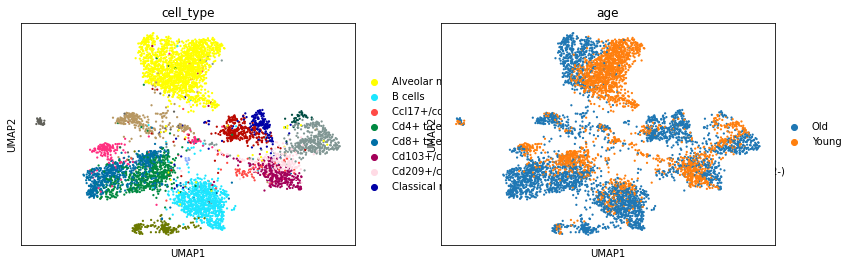

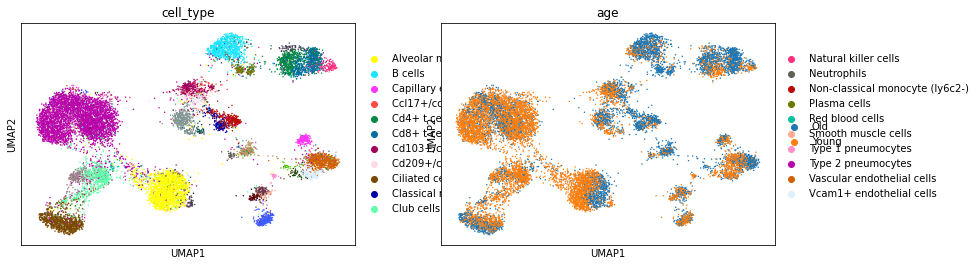

In [41]:
sc.pl.umap(adata_immune, color=['cell_type', 'age'])
sc.pl.umap(adata, color=['cell_type', 'age'])

In [42]:
df_comp = pd.DataFrame()
mice = set(adata_immune.obs['mouse'])
cell_types = set(adata_immune.obs['cell_type'])

for mouse in mice:
    for ct in cell_types:
        count = adata_immune[(adata_immune.obs['mouse']==mouse) & (adata_immune.obs['cell_type']==ct)].shape[0] # same mouse, same cell-type
        total = adata_immune[adata_immune.obs['mouse']==mouse].shape[0] # same mouse, all cell types
        other = total - count # same mouse, cell types other than ct
        
        # Fill in dataframe
        group_id = f'{ct}_{mouse}'
        
        df_comp.loc[group_id, 'Cell_type'] = ct
        df_comp.loc[group_id, 'Mouse'] = mouse
        df_comp.loc[group_id, 'Age'] = adata_immune[adata_immune.obs['mouse']==mouse].obs['age'][0] #it is impossible for the same mouse to have two different ages
        
        df_comp.loc[group_id, 'Count'] = count
        df_comp.loc[group_id, 'Other'] = other
        df_comp.loc[group_id, 'Total'] = total
df_comp.to_csv('../../output/tables/cell_type_enrichment/input/Angelidis_input_for_enrichment_immune.csv')

In [43]:
df_comp

,Cell_type,Mouse,Age,Count,Other,Total
Cd209+/cd11b+ dendritic cells_muc4167,Cd209+/cd11b+ dendritic cells,muc4167,Old,15.0,356.0,371.0
Classical monocyte (ly6c2+)_muc4167,Classical monocyte (ly6c2+),muc4167,Old,8.0,363.0,371.0
Ccl17+/cd103-/cd11b- dendritic cells_muc4167,Ccl17+/cd103-/cd11b- dendritic cells,muc4167,Old,5.0,366.0,371.0
Cd4+ t cells_muc4167,Cd4+ t cells,muc4167,Old,37.0,334.0,371.0
Plasma cells_muc4167,Plasma cells,muc4167,Old,15.0,356.0,371.0
...,...,...,...,...,...,...
Cd8+ t cells_muc4168,Cd8+ t cells,muc4168,Old,254.0,701.0,955.0
Eosinophils_muc4168,Eosinophils,muc4168,Old,15.0,940.0,955.0
Cd103+/cd11b- dendritic cells_muc4168,Cd103+/cd11b- dendritic cells,muc4168,Old,17.0,938.0,955.0
Non-classical monocyte (ly6c2-)_muc4168,Non-classical monocyte (ly6c2-),muc4168,Old,80.0,875.0,955.0


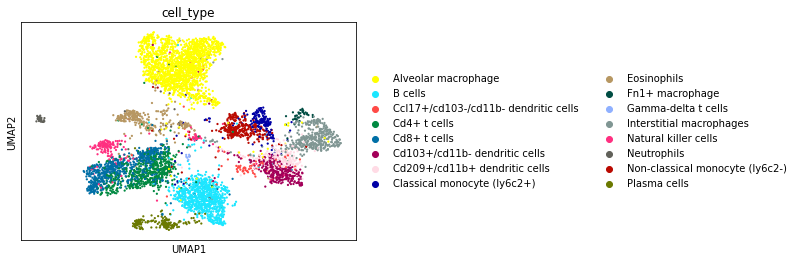

In [44]:
  sc.pl.umap(adata_immune, color='cell_type')

In [46]:
adata_immune.write('../../data/anndatas/immune/Angelidis_immune.h5ad')